In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

In [3]:
df = pd.read_csv("course_lead_scoring_2026.csv")

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (5000, 9)


In [5]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [7]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [8]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64

In [9]:
categorical_columns = df.select_dtypes(include=["object", "category"]).columns
numerical_columns = df.select_dtypes(include=np.number).columns

df[categorical_columns] = df[categorical_columns].fillna("NA")
df[numerical_columns] = df[numerical_columns].fillna(0.0)

In [10]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [11]:
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1
)

In [12]:
print("Full train:", len(df_full_train))
print("Train:", len(df_train))
print("Validation:", len(df_val))
print("Test:", len(df_test))

Full train: 4000
Train: 3000
Validation: 1000
Test: 1000


In [13]:
y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values

In [14]:
numerical = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

In [15]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])

    # If AUC is below 0.5, reverse the direction
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])

    print(f"{col:30s} {auc:.4f}")

lead_score                     0.7882
number_of_courses_viewed       0.7230
interaction_count              0.7649
annual_income                  0.6082


In [16]:
auc_results = []

for col in numerical:
    original_auc = roc_auc_score(y_train, df_train[col])

    if original_auc < 0.5:
        final_auc = roc_auc_score(y_train, -df_train[col])
    else:
        final_auc = original_auc

    auc_results.append({
        "feature": col,
        "original_auc": original_auc,
        "final_auc": final_auc
    })

auc_df = pd.DataFrame(auc_results)

auc_df.sort_values("final_auc", ascending=False)

,feature,original_auc,final_auc
0,lead_score,0.788225,0.788225
2,interaction_count,0.764920,0.764920
1,number_of_courses_viewed,0.722989,0.722989
3,annual_income,0.608198,0.608198


In [17]:
target = "converted"

X_train_df = df_train.drop(columns=[target])
X_val_df = df_val.drop(columns=[target])

y_train = df_train[target].values
y_val = df_val[target].values

In [18]:
train_dicts = X_train_df.to_dict(orient="records")
val_dicts = X_val_df.to_dict(orient="records")

In [19]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [20]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (3000, 28)
X_val: (1000, 28)


In [21]:
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [22]:
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print("Validation AUC:", auc)
print("Validation AUC rounded:", round(auc, 3))

Validation AUC: 0.7318222288173319
Validation AUC rounded: 0.732


In [23]:
thresholds = np.arange(0.0, 1.01, 0.01)

scores = []

for threshold in thresholds:
    y_pred_binary = (y_pred >= threshold).astype(int)

    precision = precision_score(
        y_val,
        y_pred_binary,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_binary,
        zero_division=0
    )

    scores.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall
    })

scores_df = pd.DataFrame(scores)

scores_df.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


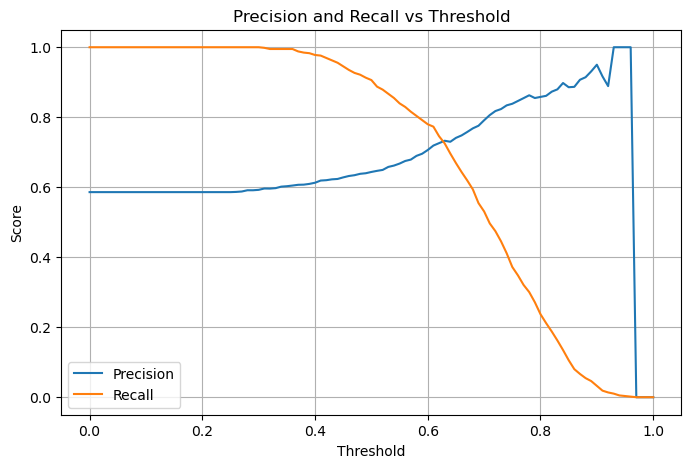

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    scores_df["threshold"],
    scores_df["precision"],
    label="Precision"
)

plt.plot(
    scores_df["threshold"],
    scores_df["recall"],
    label="Recall"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold")
plt.legend()
plt.grid()

plt.show()

In [25]:
valid_scores = scores_df[
    ~(
        (scores_df["precision"] == 0) &
        (scores_df["recall"] == 0)
    )
].copy()

valid_scores["difference"] = abs(
    valid_scores["precision"] -
    valid_scores["recall"]
)

intersection = valid_scores.loc[
    valid_scores["difference"].idxmin()
]

intersection

threshold     0.630000
precision     0.732759
recall        0.725256
difference    0.007503
Name: 63, dtype: float64

In [26]:
print("Threshold:", intersection["threshold"])
print("Precision:", intersection["precision"])
print("Recall:", intersection["recall"])
print("Difference:", intersection["difference"])

Threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458
Difference: 0.007502647993409384


In [27]:
scores_df["f1"] = np.where(
    (scores_df["precision"] + scores_df["recall"]) > 0,
    2 * scores_df["precision"] * scores_df["recall"] /
    (scores_df["precision"] + scores_df["recall"]),
    0
)

scores_df.head()

,threshold,precision,recall,f1
0,0.00,0.586,1.0,0.738966
1,0.01,0.586,1.0,0.738966
2,0.02,0.586,1.0,0.738966
3,0.03,0.586,1.0,0.738966
4,0.04,0.586,1.0,0.738966


In [28]:
best_f1 = scores_df.loc[
    scores_df["f1"].idxmax()
]

best_f1

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

In [29]:
print("Best threshold:", best_f1["threshold"])
print("Maximum F1:", best_f1["f1"])

Best threshold: 0.41000000000000003
Maximum F1: 0.7576158940397352


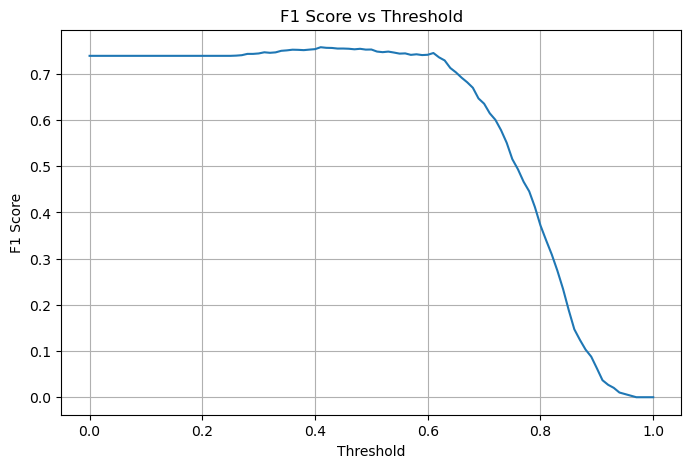

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    scores_df["threshold"],
    scores_df["f1"]
)

plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs Threshold")
plt.grid()

plt.show()

In [31]:
KFold(n_splits=5, shuffle=True, random_state=1)

KFold(n_splits=5, random_state=1, shuffle=True)

In [32]:
def train(df_train, y_train, C=1.0):
    
    dicts = df_train.to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(
        solver="liblinear",
        C=C,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    return dv, model

In [33]:
def predict(df, dv, model):
    
    dicts = df.to_dict(orient="records")

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [34]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = df_train_fold["converted"].values
    y_val_fold = df_val_fold["converted"].values

    X_train_fold = df_train_fold.drop(columns=["converted"])
    X_val_fold = df_val_fold.drop(columns=["converted"])

    dv, model = train(
        X_train_fold,
        y_train_fold,
        C=1.0
    )

    y_pred_fold = predict(
        X_val_fold,
        dv,
        model
    )

    auc = roc_auc_score(
        y_val_fold,
        y_pred_fold
    )

    scores.append(auc)

In [35]:
for i, score in enumerate(scores, start=1):
    print(f"Fold {i}: {score:.4f}")

Fold 1: 0.7306
Fold 2: 0.7296
Fold 3: 0.7363
Fold 4: 0.7412
Fold 5: 0.7209


In [36]:
for i, score in enumerate(scores, start=1):
    print(f"Fold {i}: {score:.4f}")

Fold 1: 0.7306
Fold 2: 0.7296
Fold 3: 0.7363
Fold 4: 0.7412
Fold 5: 0.7209


In [37]:
print("Mean AUC:", np.mean(scores))
print("Standard deviation:", np.std(scores))
print("Rounded std:", round(np.std(scores), 3))

Mean AUC: 0.7317269710972524
Standard deviation: 0.006853233151022138
Rounded std: 0.007


In [38]:
C_values = [
    0.000001,
    0.001,
    1
]

In [39]:
C_values = [0.000001, 0.001, 1]

results = []

for C in C_values:

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        y_train_fold = df_train_fold["converted"].values
        y_val_fold = df_val_fold["converted"].values

        X_train_fold = df_train_fold.drop(
            columns=["converted"]
        )

        X_val_fold = df_val_fold.drop(
            columns=["converted"]
        )

        dv, model = train(
            X_train_fold,
            y_train_fold,
            C=C
        )

        y_pred_fold = predict(
            X_val_fold,
            dv,
            model
        )

        auc = roc_auc_score(
            y_val_fold,
            y_pred_fold
        )

        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    results.append({
        "C": C,
        "mean_auc": mean_auc,
        "std_auc": std_auc
    })

    print(
        f"C={C:<10} "
        f"Mean AUC={mean_auc:.3f} "
        f"Std={std_auc:.3f}"
    )

C=1e-06      Mean AUC=0.617 Std=0.019
C=0.001      Mean AUC=0.749 Std=0.010
C=1          Mean AUC=0.732 Std=0.007


In [40]:
results_df = pd.DataFrame(results)

results_df

,C,mean_auc,std_auc
0,0.000001,0.616734,0.018670
1,0.001000,0.749172,0.009996
2,1.000000,0.731727,0.006853


In [41]:
results_df = pd.DataFrame(results)

results_df

,C,mean_auc,std_auc
0,0.000001,0.616734,0.018670
1,0.001000,0.749172,0.009996
2,1.000000,0.731727,0.006853


In [42]:
results_df["mean_auc_rounded"] = results_df["mean_auc"].round(3)
results_df["std_auc_rounded"] = results_df["std_auc"].round(3)

results_df

,C,mean_auc,std_auc,mean_auc_rounded,std_auc_rounded
0,0.000001,0.616734,0.018670,0.617,0.019
1,0.001000,0.749172,0.009996,0.749,0.010
2,1.000000,0.731727,0.006853,0.732,0.007


In [43]:
best_result = (
    results_df
    .sort_values(
        by=[
            "mean_auc_rounded",
            "std_auc_rounded",
            "C"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
    .iloc[0]
)

print("Best C:", best_result["C"])
print("Mean AUC:", best_result["mean_auc_rounded"])
print("Std:", best_result["std_auc_rounded"])

Best C: 0.001
Mean AUC: 0.749
Std: 0.01
